## Post Updates

Update 11/1/2026: Split this post into two parts. This post now covers the correlations and rolling correlations, and the total correlation metric, decile analysis, and trading strategy have moved to [part 2](/posts/asset-class-return-correlations-part-2/).

## Introduction

In this post, we'll take a look at historical return correlations between asset classes, including rolling correlations and how those correlations have changed over time. Since first publishing this post, we've split it into two parts, and [part 2](/posts/asset-class-return-correlations-part-2/) uses these correlations to build a market timing signal and a trading strategy.

 ## Python Imports

In [1]:
# Standard Library
import os
import sys
import warnings

from IPython.display import display, Markdown
from itertools import combinations, count
from pathlib import Path

# Data Handling
import pandas as pd

# Suppress warnings
warnings.filterwarnings("ignore")

# Pandas display options
pd.set_option("display.float_format", lambda x: f"%.2f" % x)

In [2]:
# Add the source subdirectory to the system path to allow import config from settings.py
current_directory = Path(os.getcwd())
BASE_DIR = current_directory.parent.parent.parent
src_directory = BASE_DIR / "src"
sys.path.append(str(src_directory)) if str(src_directory) not in sys.path else None

# Import settings.py
from settings import config

# Add other configured directories
CONTENT_DIR = config("CONTENT_DIR")
POSTS_DIR = config("POSTS_DIR")
PAGES_DIR = config("PAGES_DIR")
PUBLIC_DIR = config("PUBLIC_DIR")
SOURCE_DIR = config("SOURCE_DIR")
DATA_DIR = config("DATA_DIR")
DATA_MANUAL_DIR = config("DATA_MANUAL_DIR")

## Python Functions

Here are the functions needed for this project:

* [load_data](/posts/reusable-extensible-python-functions-financial-data-analysis/#load_data): Load data from a CSV, Excel, or Pickle file into a pandas DataFrame.
* [plot_time_series](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_time_series): Plot the timeseries data from a DataFrame for a specified date range and columns.
* [yf_pull_data](/posts/reusable-extensible-python-functions-financial-data-analysis/#yf_pull_data): Download daily price data from Yahoo Finance and export it.

In [3]:
from load_data import load_data
from plot_heatmap import plot_heatmap
from plot_time_series import plot_time_series
from yf_pull_data import yf_pull_data

## Data Overview

For this exercise, we will (mostly) use ETFs as a proxy for asset classes and will use the following:

* Large Cap US Stocks / S&P 500 -- IVV (iShares S&P 500 ETF)
* Mid Cap US Stocks / S&P MidCap 400 -- IJH (iShares S&P MidCap 400 ETF)
* Small Cap US Stocks / S&P SmallCap 600 -- IJR (iShares S&P SmallCap 600 ETF)
* US Tech Stocks / Nasdaq 100 -- QQQ (Invesco QQQ Trust, Series 1)
* Large & Mid Cap US Stocks -- IWB (iShares Russell 1000 ETF)
* Small Cap US Stocks -- IWM (iShares Russell 2000 ETF)
* US Value Stocks -- IWD (iShares Russell 1000 Value ETF)
* US Growth Stocks -- IWF (iShares Russell 1000 Growth ETF)
* International Developed Market Stocks -- EFA (iShares MSCI EAFE ETF)
* Emerging Market Stocks -- EEM (iShares MSCI Emerging Markets ETF)
* European Stocks -- IEV (iShares S&P Europe 350 ETF)
* Short-Term US Treasuries -- SHY (iShares 1-3 Year Treasury Bond ETF)
* Medium-Term US Treasuries -- IEF (iShares 7-10 Year Treasury Bond ETF)
* Long-Term US Treasuries -- TLT (iShares 20+ Year Treasury Bond ETF)
* Aggregate Bonds -- AGG (iShares Core U.S. Aggregate Bond ETF)
* Gold -- GLD (SPDR Gold Shares)
* Commodities -- GSG (iShares S&P GSCI Commodity-Indexed Trust)
* Real Estate -- IYR (iShares U.S. Real Estate ETF)
* Bitcoin -- BTC-USD (Bitcoin USD)
* Ethereum -- ETH-USD (Ethereum USD)

For all of these, we will use the adjusted closing price, which accounts for dividends and stock splits.

### Acquire & Plot Data

We'll now pull the data for all the ETFs and cryptocurrencies listed above.

In [4]:
figure_number = count(1)
table_number = count(1)

# Create list of tickers to pull data for
us_equity_tickers = ["IVV", "IJH", "IJR", "QQQ", "IWB", "IWD", "IWF", "IWM"]
intl_equity_tickers = ["EFA", "EEM", "IEV"]
equity_tickers = us_equity_tickers + intl_equity_tickers
bond_tickers = ["SHY", "IEF", "TLT", "AGG"]
commodity_tickers = ["GLD", "GSG"]
real_estate_tickers = ["IYR"]
cryptoasset_tickers = ["BTC-USD", "ETH-USD"]

etf_tickers = (
    us_equity_tickers
    + intl_equity_tickers
    + bond_tickers
    + commodity_tickers
    + real_estate_tickers
)

tickers_dict = {
    "IVV": "Large Cap US Stocks / S&P 500 -- IVV (iShares S&P 500 ETF)",
    "IJH": "Mid Cap US Stocks / S&P MidCap 400 -- IJH (iShares S&P MidCap 400 ETF)",
    "IJR": "Small Cap US Stocks / S&P SmallCap 600 -- IJR (iShares S&P SmallCap 600 ETF)",
    "QQQ": "US Tech Stocks / Nasdaq 100 -- QQQ (Invesco QQQ Trust, Series 1)",
    "IWB": "Large & Mid Cap US Stocks -- IWB (iShares Russell 1000 ETF)",
    "IWM": "Small Cap US Stocks -- IWM (iShares Russell 2000 ETF)",
    "IWD": "Large & Mid Cap US Value Stocks -- IWD (iShares Russell 1000 Value ETF)",
    "IWF": "Large & Mid Cap US Growth Stocks -- IWF (iShares Russell 1000 Growth ETF)",
    "EFA": "International Developed Market Stocks -- EFA (iShares MSCI EAFE ETF)",
    "EEM": "Emerging Market Stocks -- EEM (iShares MSCI Emerging Markets ETF)",
    "IEV": "European Stocks -- IEV (iShares S&P Europe 350 ETF)",
    "SHY": "Short-Term US Treasuries -- SHY (iShares 1-3 Year Treasury Bond ETF)",
    "IEF": "Medium-Term US Treasuries -- IEF (iShares 7-10 Year Treasury Bond ETF)",
    "TLT": "Long-Term US Treasuries -- TLT (iShares 20+ Year Treasury Bond ETF)",
    "AGG": "Aggregate Bonds -- AGG (iShares Core U.S. Aggregate Bond ETF)",
    "GLD": "Gold -- GLD (SPDR Gold Shares)",
    "GSG": "Commodities -- GSG (iShares S&P GSCI Commodity-Indexed Trust)",
    "IYR": "Real Estate -- IYR (iShares U.S. Real Estate ETF)",
    "BTC-USD": "Bitcoin -- BTC-USD (Bitcoin USD)",
    "ETH-USD": "Ethereum -- ETH-USD (Ethereum USD)",
}

In [5]:
for ticker in etf_tickers:
    yf_pull_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        adjusted=False,
        source="Yahoo_Finance",
        asset_class="Exchange_Traded_Funds",
        excel_export=True,
        pickle_export=True,
        output_confirmation=False,
    )

for ticker in cryptoasset_tickers:
    yf_pull_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        adjusted=False,
        source="Yahoo_Finance",
        asset_class="Cryptocurrencies",
        excel_export=True,
        pickle_export=True,
        output_confirmation=False,
    )

### Load & Filter Data

We'll then peform the following:
* Load data
* Rename columns to include the ticker (e.g. "QQQ_Close", "QQQ_Adj_Close", etc.)
* Drop all columns except for "Adj Close"
* Calculate the daily returns
* Combine the data into a single DataFrame
* Check the inception date for each of thge funds

In [6]:
fund_data = pd.DataFrame()

for ticker in etf_tickers:
    data = load_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        source="Yahoo_Finance",
        asset_class="Exchange_Traded_Funds",
        timeframe="Daily",
        file_format="pickle",
    )

    # Rename columns to "QQQ_Close", etc.
    data = data.rename(
        columns={
            "Adj Close": f"{ticker}_Adj_Close",
            "Close": f"{ticker}_Close",
            "High": f"{ticker}_High",
            "Low": f"{ticker}_Low",
            "Open": f"{ticker}_Open",
            "Volume": f"{ticker}_Volume",
        }
    )

    # Drop all columns except for the adjusted close price and date index
    data = data[[f"{ticker}_Adj_Close"]]

    # Calculate daily returns and add as new column
    data[f"{ticker}_Daily_Return"] = data[f"{ticker}_Adj_Close"].pct_change()

    # Concatenate the data for this ticker with the main fund_data DataFrame
    fund_data = pd.concat([fund_data, data], axis=1)

for ticker in cryptoasset_tickers:
    data = load_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        source="Yahoo_Finance",
        asset_class="Cryptocurrencies",
        timeframe="Daily",
        file_format="pickle",
    )

    # Rename columns to "BTC-USD_Close", etc.
    data = data.rename(
        columns={
            "Adj Close": f"{ticker}_Adj_Close",
            "Close": f"{ticker}_Close",
            "High": f"{ticker}_High",
            "Low": f"{ticker}_Low",
            "Open": f"{ticker}_Open",
            "Volume": f"{ticker}_Volume",
        }
    )

    # Drop all columns except for the adjusted close price and date index
    data = data[[f"{ticker}_Adj_Close"]]

    # Calculate daily returns and add as new column
    data[f"{ticker}_Daily_Return"] = data[f"{ticker}_Adj_Close"].pct_change()

    # Concatenate the data for this ticker with the main fund_data DataFrame
    fund_data = pd.concat([fund_data, data], axis=1)

display(Markdown(f"Table {next(table_number)}: Fund Data"))
display(fund_data)

Table 1: Fund Data

,IVV_Adj_Close,IVV_Daily_Return,IJH_Adj_Close,IJH_Daily_Return,IJR_Adj_Close,IJR_Daily_Return,QQQ_Adj_Close,QQQ_Daily_Return,IWB_Adj_Close,IWB_Daily_Return,...,GLD_Adj_Close,GLD_Daily_Return,GSG_Adj_Close,GSG_Daily_Return,IYR_Adj_Close,IYR_Daily_Return,BTC-USD_Adj_Close,BTC-USD_Daily_Return,ETH-USD_Adj_Close,ETH-USD_Daily_Return
Date,,,,,,,,,,,,,,,,,,,,,
1999-03-10,NaN,NaN,NaN,NaN,NaN,NaN,42.98,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-11,NaN,NaN,NaN,NaN,NaN,NaN,43.19,0.00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-12,NaN,NaN,NaN,NaN,NaN,NaN,42.14,-0.02,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-15,NaN,NaN,NaN,NaN,NaN,NaN,43.35,0.03,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-16,NaN,NaN,NaN,NaN,NaN,NaN,43.72,0.01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-27,773.25,0.01,73.22,0.00,139.68,0.01,721.25,0.01,420.41,0.01,...,372.28,0.01,36.99,-0.01,97.97,-0.01,80805.08,0.01,2347.73,0.01
2026-10-28,775.65,0.00,73.35,0.00,139.76,0.00,725.61,0.01,421.72,0.00,...,373.51,0.00,37.15,0.00,97.29,-0.01,81267.59,0.01,2357.62,0.00
2026-10-29,772.97,-0.00,74.20,0.01,142.01,0.02,715.34,-0.01,420.52,-0.00,...,368.57,-0.01,37.11,-0.00,99.47,0.02,77775.11,-0.04,2249.50,-0.05


In [7]:
for ticker in tickers_dict.keys():
    print(f"First date for {ticker}: {fund_data[f'{ticker}_Daily_Return'].first_valid_index()}")

First date for IVV: 2000-05-22 00:00:00
First date for IJH: 2000-05-30 00:00:00
First date for IJR: 2000-05-30 00:00:00
First date for QQQ: 1999-03-11 00:00:00
First date for IWB: 2000-05-22 00:00:00
First date for IWM: 2000-05-30 00:00:00
First date for IWD: 2000-05-30 00:00:00
First date for IWF: 2000-05-30 00:00:00
First date for EFA: 2001-08-28 00:00:00
First date for EEM: 2003-04-15 00:00:00
First date for IEV: 2000-07-31 00:00:00
First date for SHY: 2002-07-31 00:00:00
First date for IEF: 2002-07-31 00:00:00
First date for TLT: 2002-07-31 00:00:00
First date for AGG: 2003-09-30 00:00:00
First date for GLD: 2004-11-19 00:00:00
First date for GSG: 2006-07-24 00:00:00
First date for IYR: 2000-06-20 00:00:00
First date for BTC-USD: 2014-09-18 00:00:00
First date for ETH-USD: 2017-11-10 00:00:00


### Plot Data

We'll then plot the time series of the adjusted close prices for each of the assets.

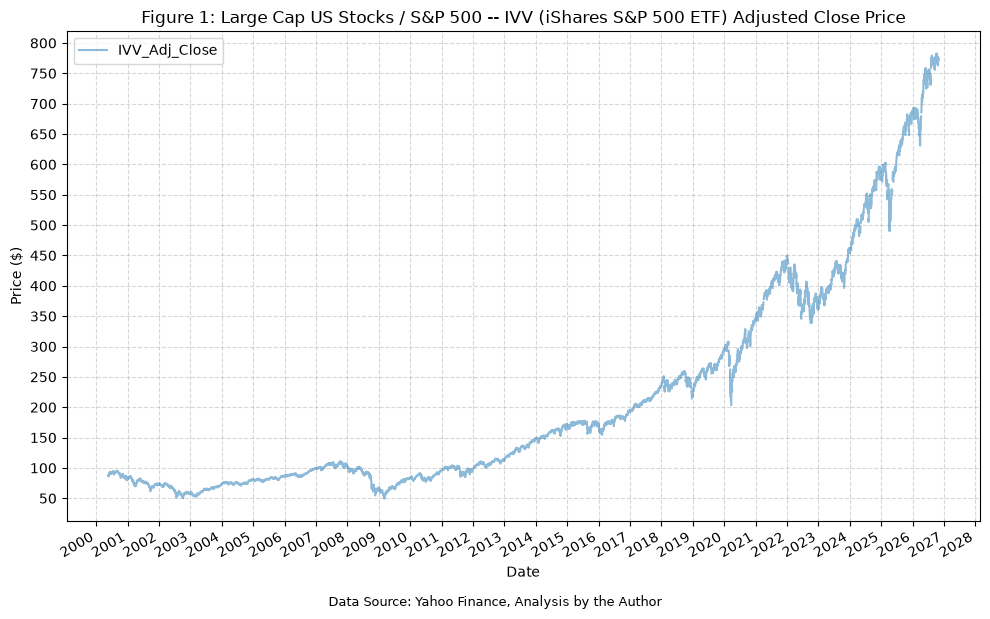

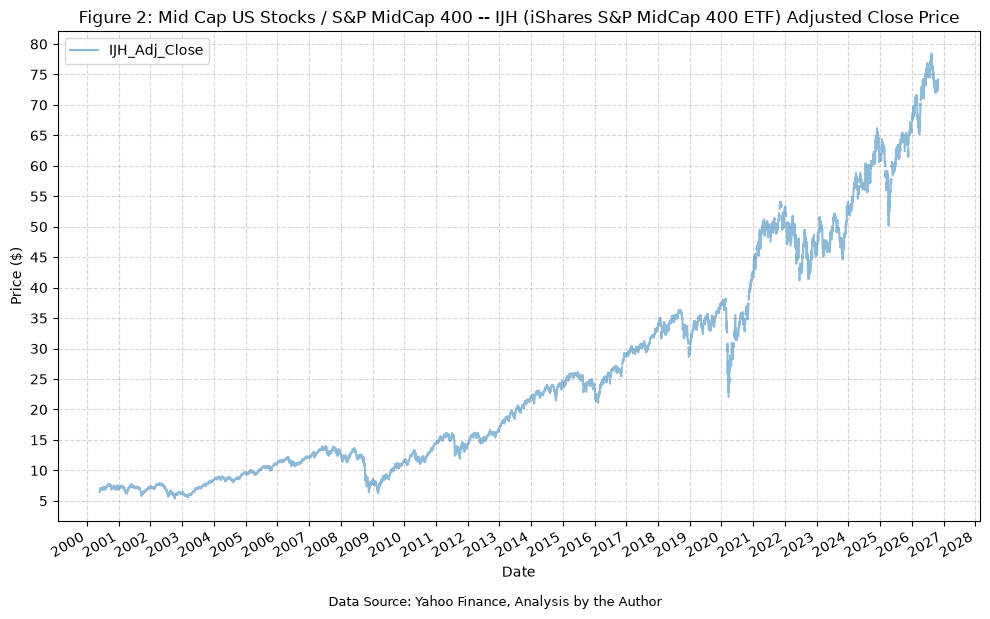

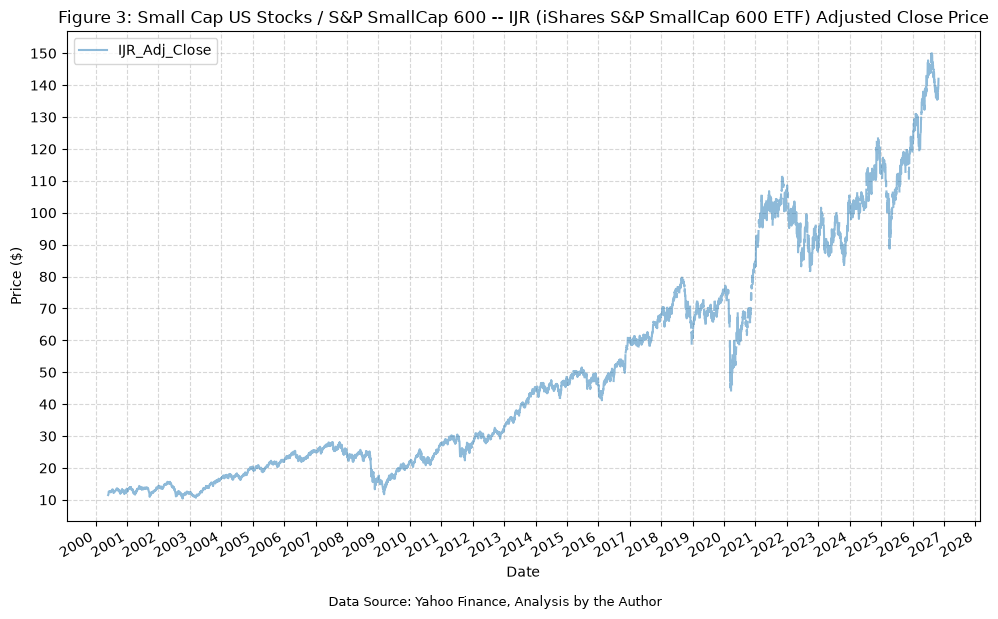

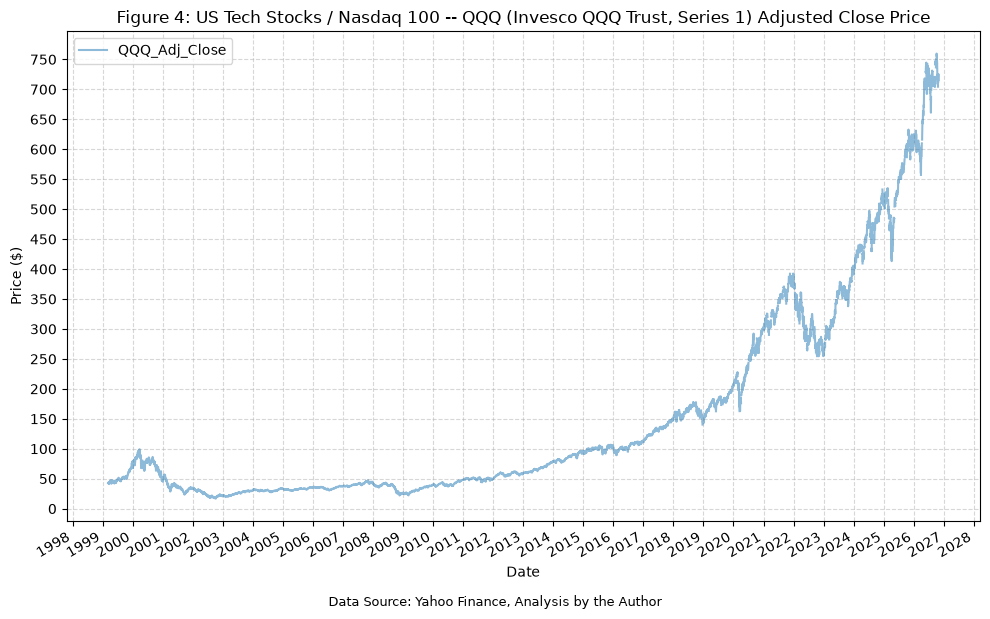

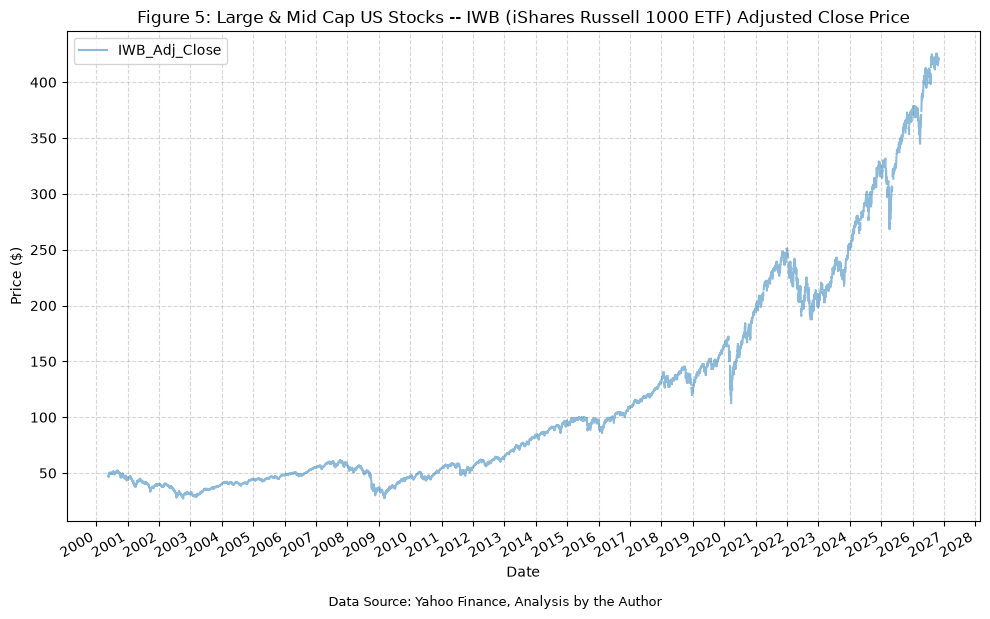

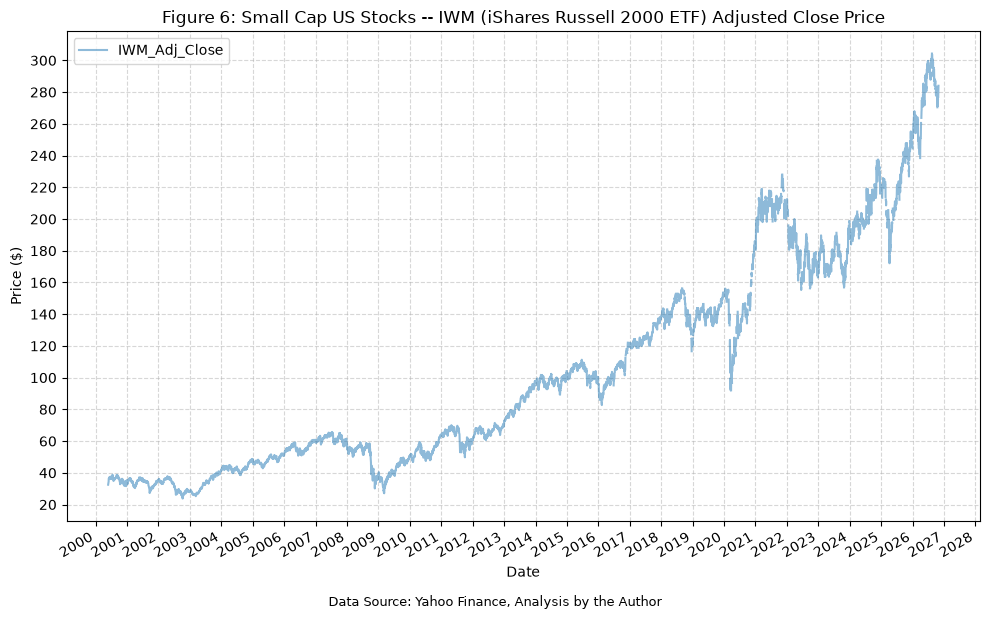

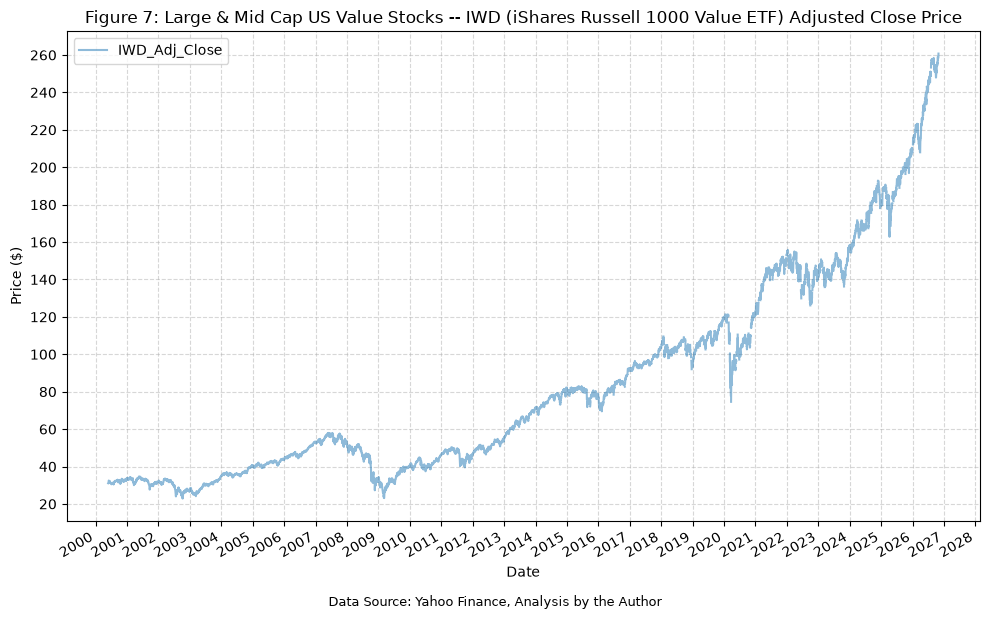

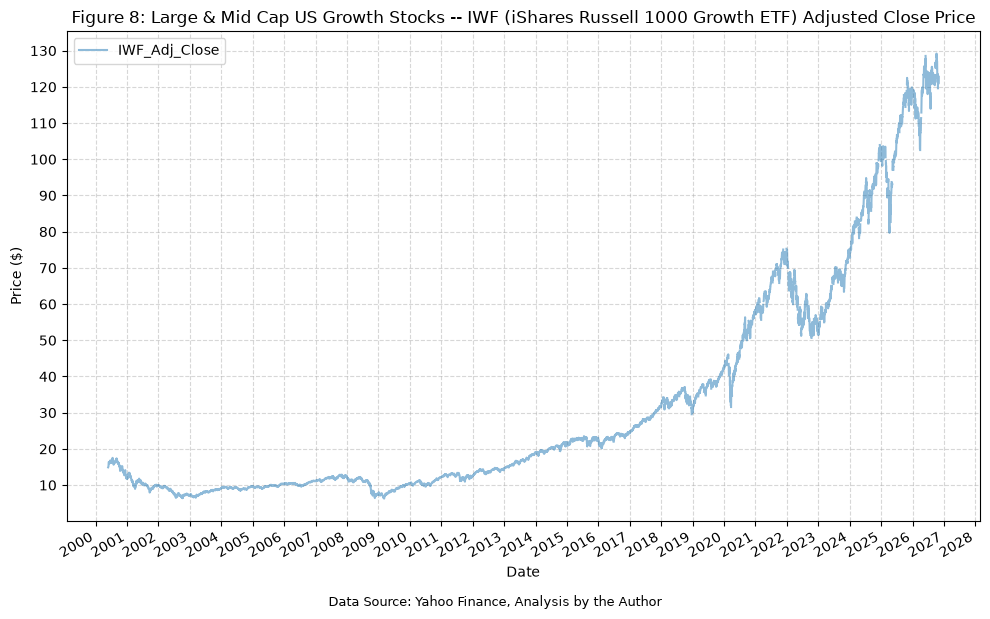

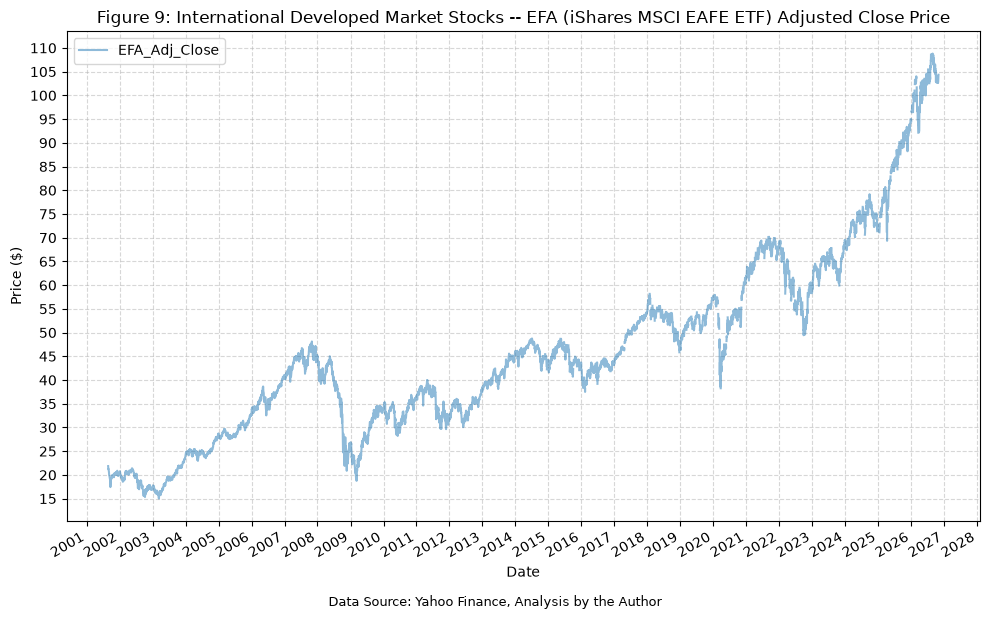

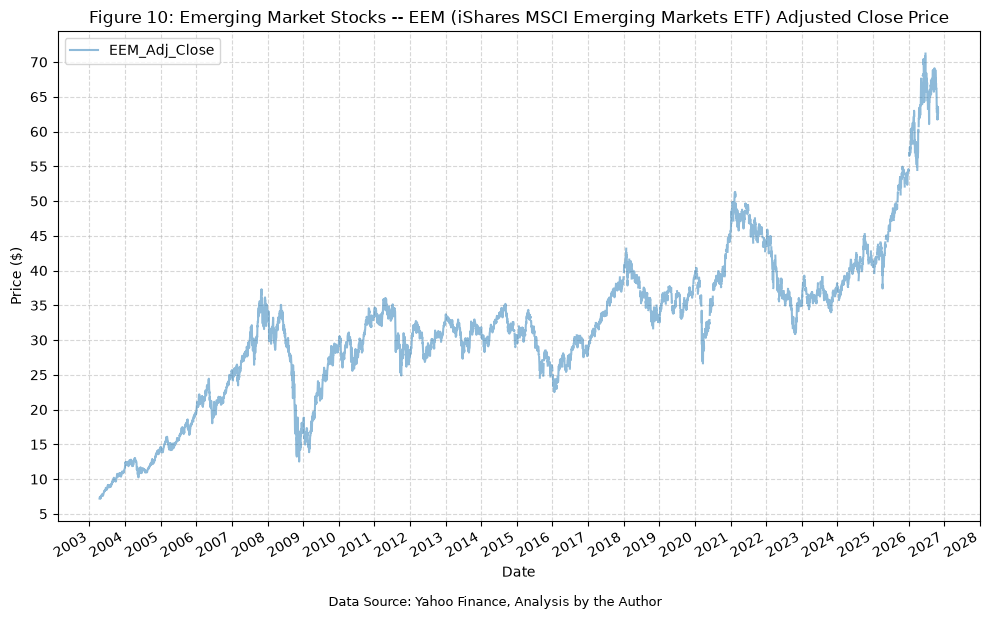

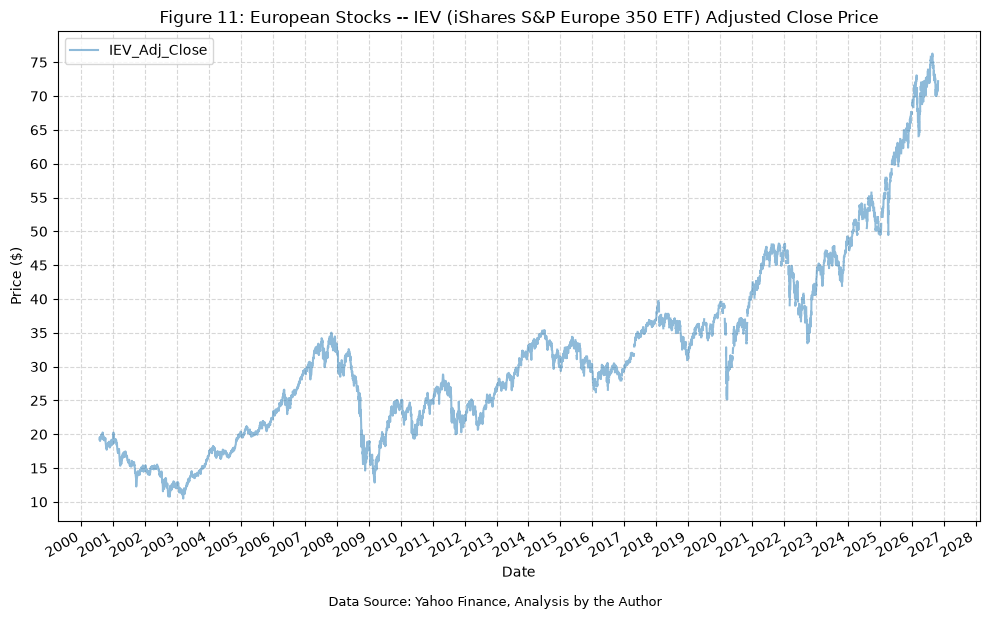

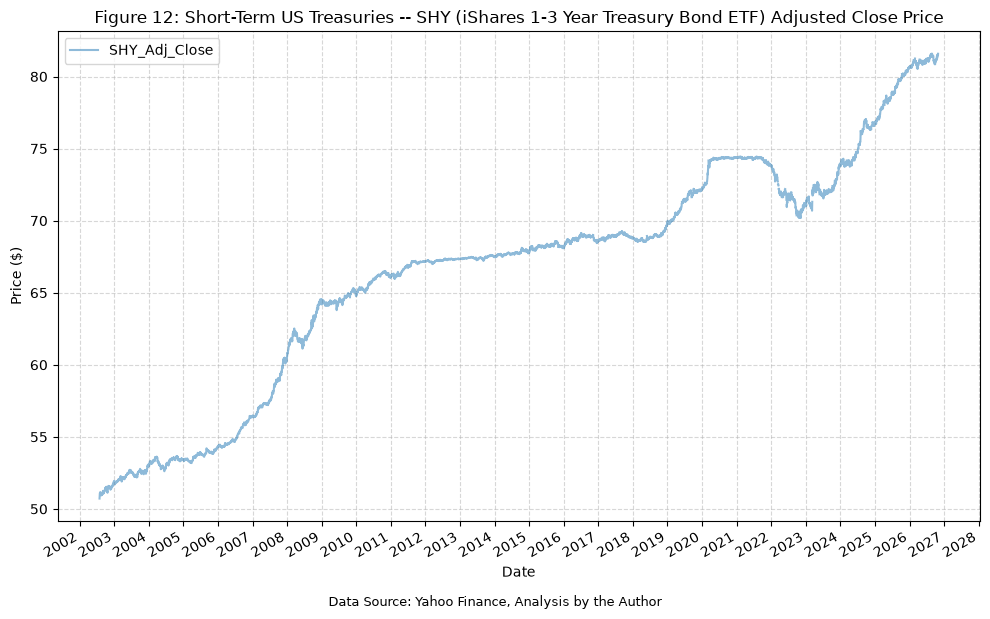

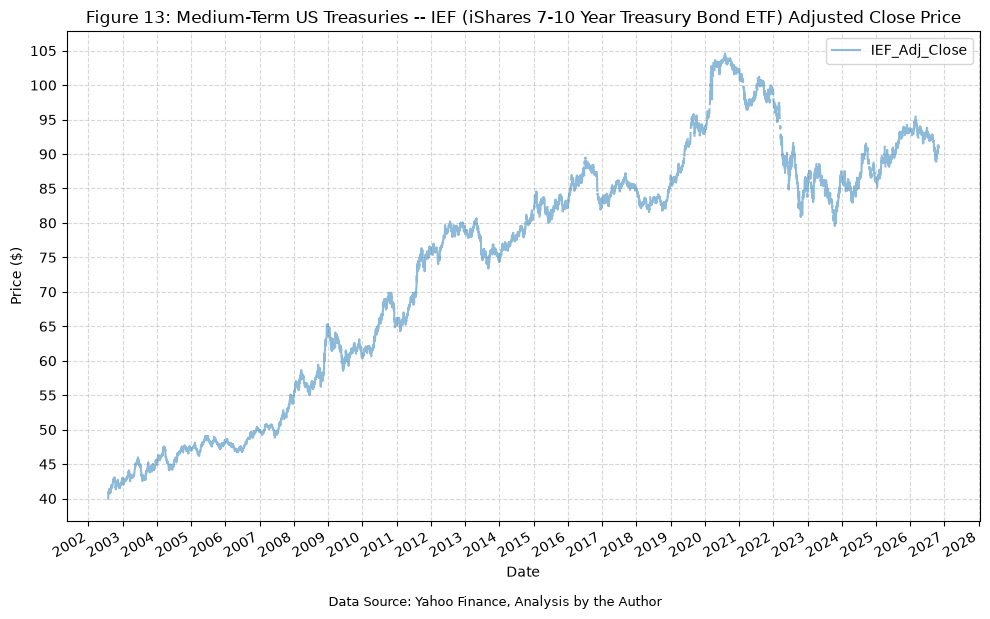

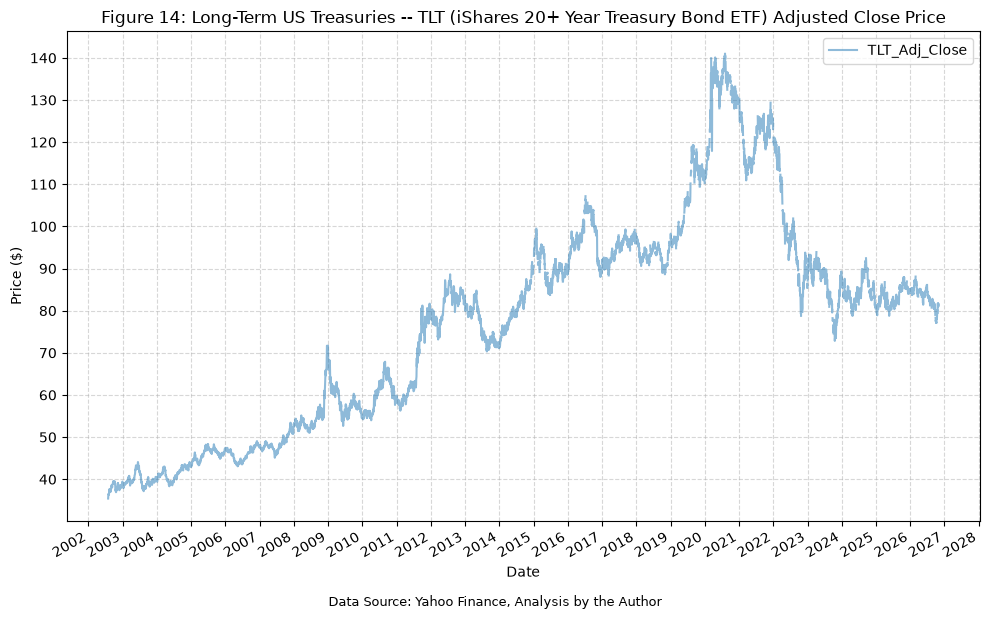

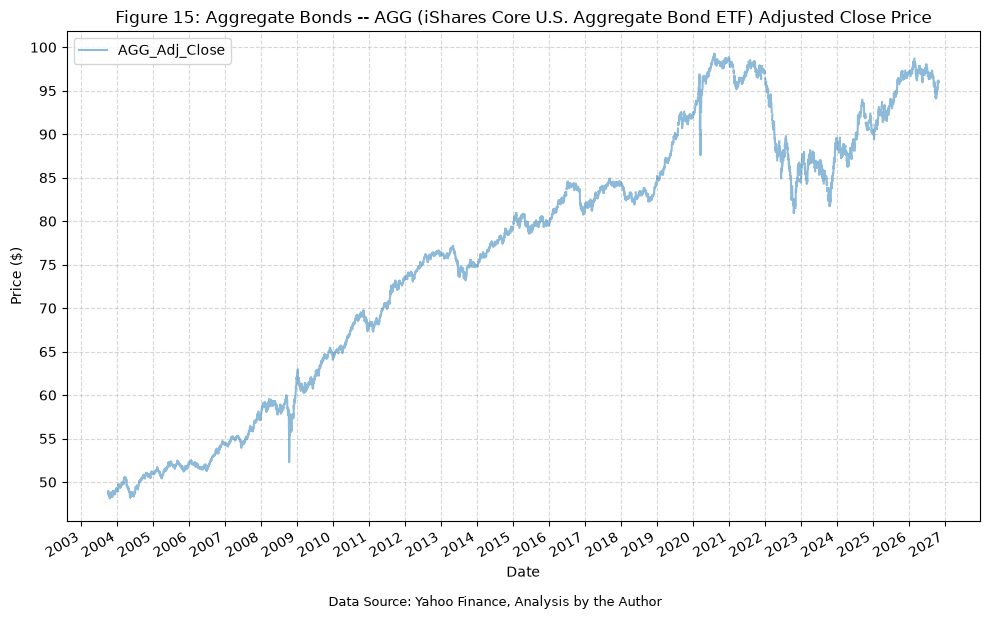

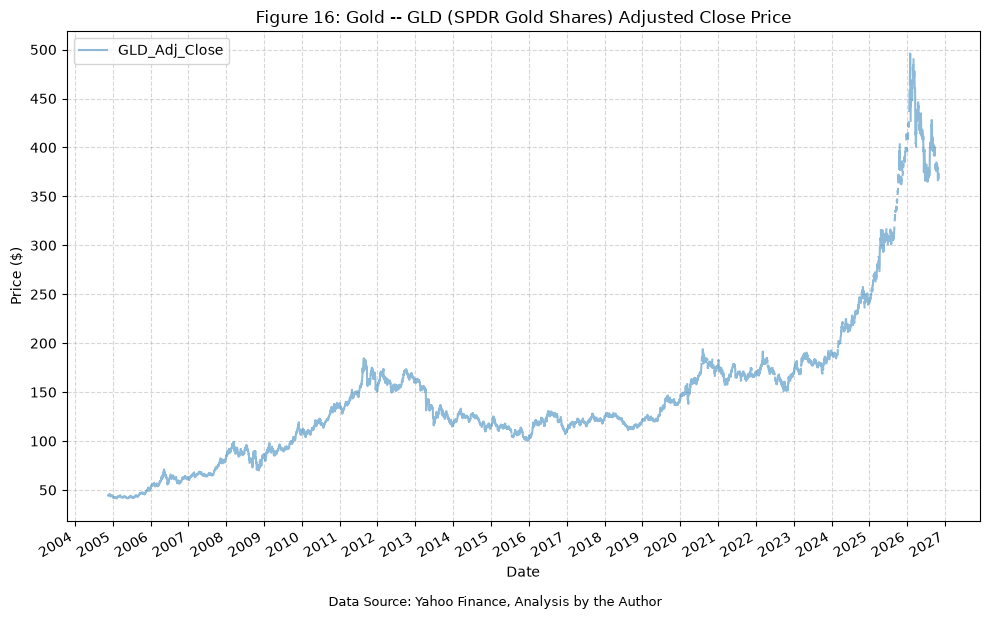

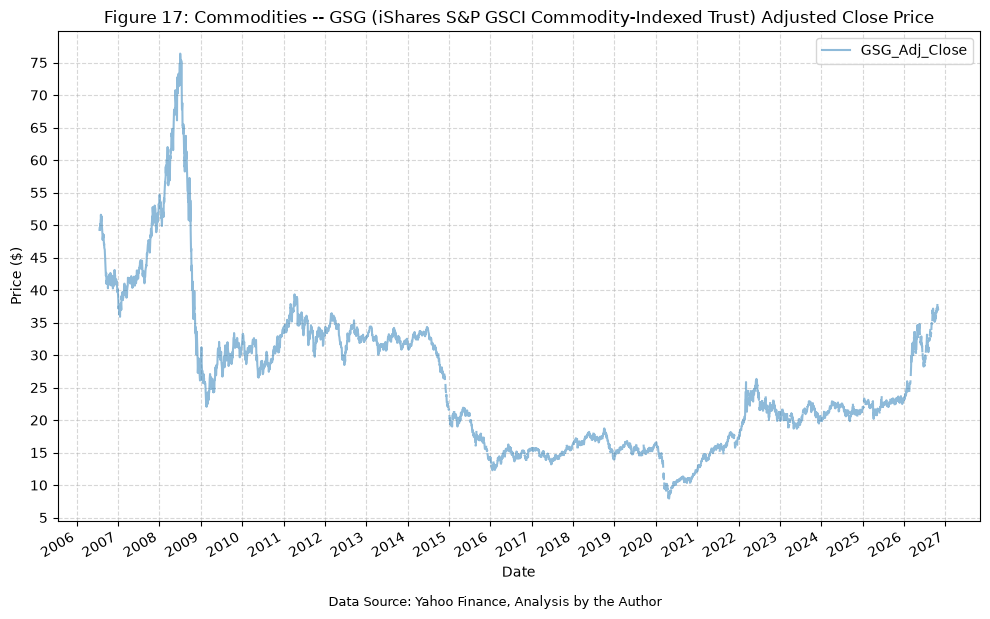

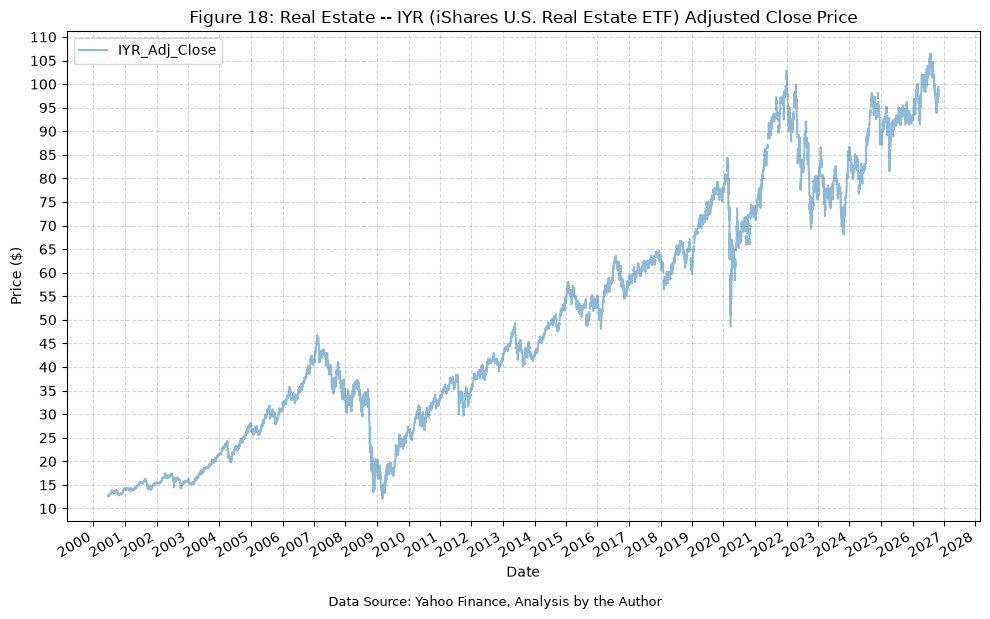

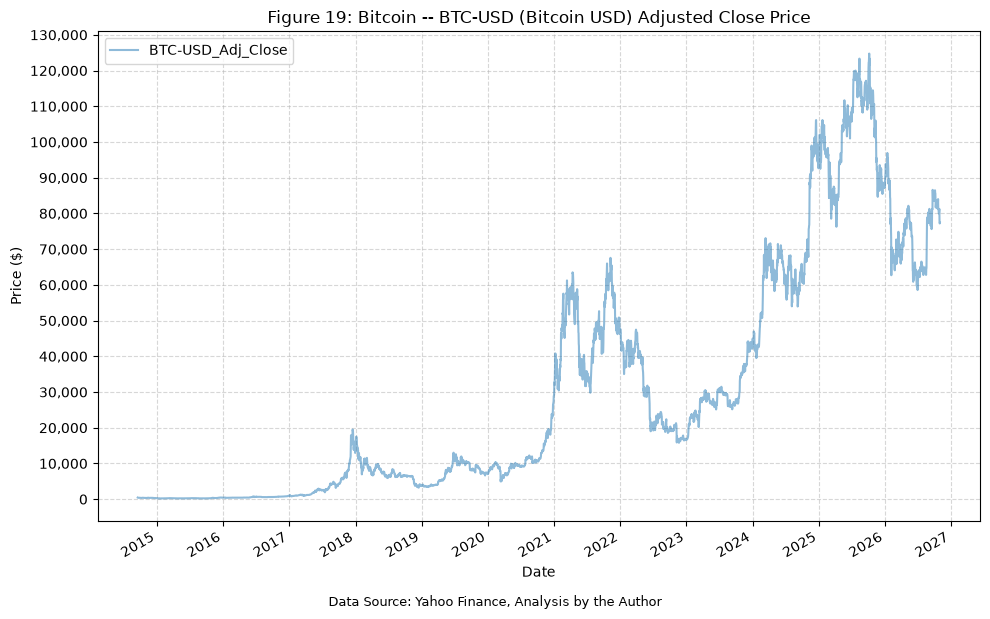

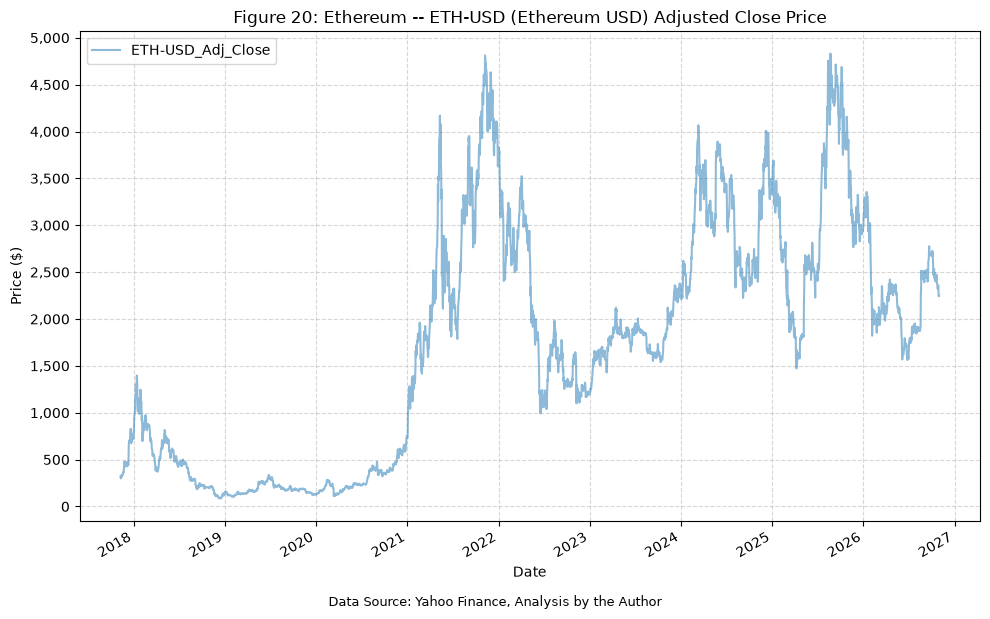

In [8]:
# Combine the etf_tickers and cryptoasset_tickers lists into a single list of all tickers
all_tickers = etf_tickers + cryptoasset_tickers

for ticker in tickers_dict.keys():
    plot_time_series(
        df=fund_data,
        plot_start_date=None,
        plot_end_date=None,
        plot_columns=[f"{ticker}_Adj_Close"],
        title=f"Figure {next(figure_number)}: {tickers_dict[ticker]} Adjusted Close Price",
        x_label="Date",
        x_format="Year",
        x_tick_spacing=1,
        x_tick_start=None,
        x_tick_rotation=30,
        y_label="Price ($)",
        y_format="Decimal",
        y_format_decimal_places="Auto",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

## Calculate Correlations

Next, we'll calculate the correlation matrix of the daily returns for all of the assets and plot it as a heatmap. We'll do this first without the BTC and ETH data (due to the limited history), and then with the BTC and ETH data.

In [9]:
# Drop the adjusted close price columns, leaving only the daily return columns
daily_return_columns = [f"{ticker}_Daily_Return" for ticker in tickers_dict.keys()]
fund_data_daily_returns_all = fund_data[daily_return_columns]

# Drop the BTC and ETH daily return columns due to the limited history
fund_data_daily_returns_no_crypto = fund_data_daily_returns_all.drop(columns=["BTC-USD_Daily_Return", "ETH-USD_Daily_Return"])

# Print the shape of the fund_data_daily_returns_no_crypto DataFrame to confirm that the rows with missing data have been dropped
print(f"Shape of fund_data_daily_returns_no_crypto: {fund_data_daily_returns_no_crypto.shape}")
print(f"Rows to drop due to missing data: {fund_data_daily_returns_no_crypto.dropna().shape}")

# Drop the NaN values
fund_data_daily_returns_no_crypto = fund_data_daily_returns_no_crypto.dropna()

# Calculate the correlation matrix of the daily returns
correlation_matrix_no_crypto = fund_data_daily_returns_no_crypto.corr()

display(Markdown(f"Table {next(table_number)}: Correlation Matrix of Daily Returns (Excluding BTC and ETH)"))
display(correlation_matrix_no_crypto)

Shape of fund_data_daily_returns_no_crypto: (8334, 18)
Rows to drop due to missing data: (5100, 18)


Table 2: Correlation Matrix of Daily Returns (Excluding BTC and ETH)

,IVV_Daily_Return,IJH_Daily_Return,IJR_Daily_Return,QQQ_Daily_Return,IWB_Daily_Return,IWM_Daily_Return,IWD_Daily_Return,IWF_Daily_Return,EFA_Daily_Return,EEM_Daily_Return,IEV_Daily_Return,SHY_Daily_Return,IEF_Daily_Return,TLT_Daily_Return,AGG_Daily_Return,GLD_Daily_Return,GSG_Daily_Return,IYR_Daily_Return
IVV_Daily_Return,1.00,0.93,0.88,0.92,1.00,0.90,0.96,0.96,0.88,0.82,0.86,-0.23,-0.30,-0.31,-0.01,0.07,0.37,0.76
IJH_Daily_Return,0.93,1.00,0.96,0.83,0.94,0.96,0.94,0.87,0.85,0.78,0.83,-0.20,-0.28,-0.30,-0.00,0.07,0.38,0.78
IJR_Daily_Return,0.88,0.96,1.00,0.78,0.89,0.98,0.90,0.82,0.80,0.73,0.78,-0.19,-0.27,-0.29,-0.03,0.05,0.35,0.76
QQQ_Daily_Return,0.92,0.83,0.78,1.00,0.93,0.82,0.81,0.97,0.79,0.76,0.76,-0.19,-0.24,-0.25,0.01,0.06,0.29,0.63
IWB_Daily_Return,1.00,0.94,0.89,0.93,1.00,0.91,0.96,0.96,0.88,0.82,0.86,-0.22,-0.29,-0.31,-0.01,0.07,0.37,0.76
IWM_Daily_Return,0.90,0.96,0.98,0.82,0.91,1.00,0.90,0.85,0.81,0.76,0.80,-0.19,-0.27,-0.28,-0.02,0.06,0.35,0.76
IWD_Daily_Return,0.96,0.94,0.90,0.81,0.96,0.90,1.00,0.86,0.88,0.80,0.86,-0.24,-0.31,-0.33,-0.01,0.06,0.39,0.80
IWF_Daily_Return,0.96,0.87,0.82,0.97,0.96,0.85,0.86,1.00,0.82,0.78,0.80,-0.19,-0.25,-0.26,0.02,0.08,0.33,0.67
EFA_Daily_Return,0.88,0.85,0.80,0.79,0.88,0.81,0.88,0.82,1.00,0.87,0.98,-0.18,-0.26,-0.28,0.04,0.17,0.40,0.70
EEM_Daily_Return,0.82,0.78,0.73,0.76,0.82,0.76,0.80,0.78,0.87,1.00,0.84,-0.21,-0.26,-0.26,-0.01,0.19,0.40,0.66


And then the heatmap:

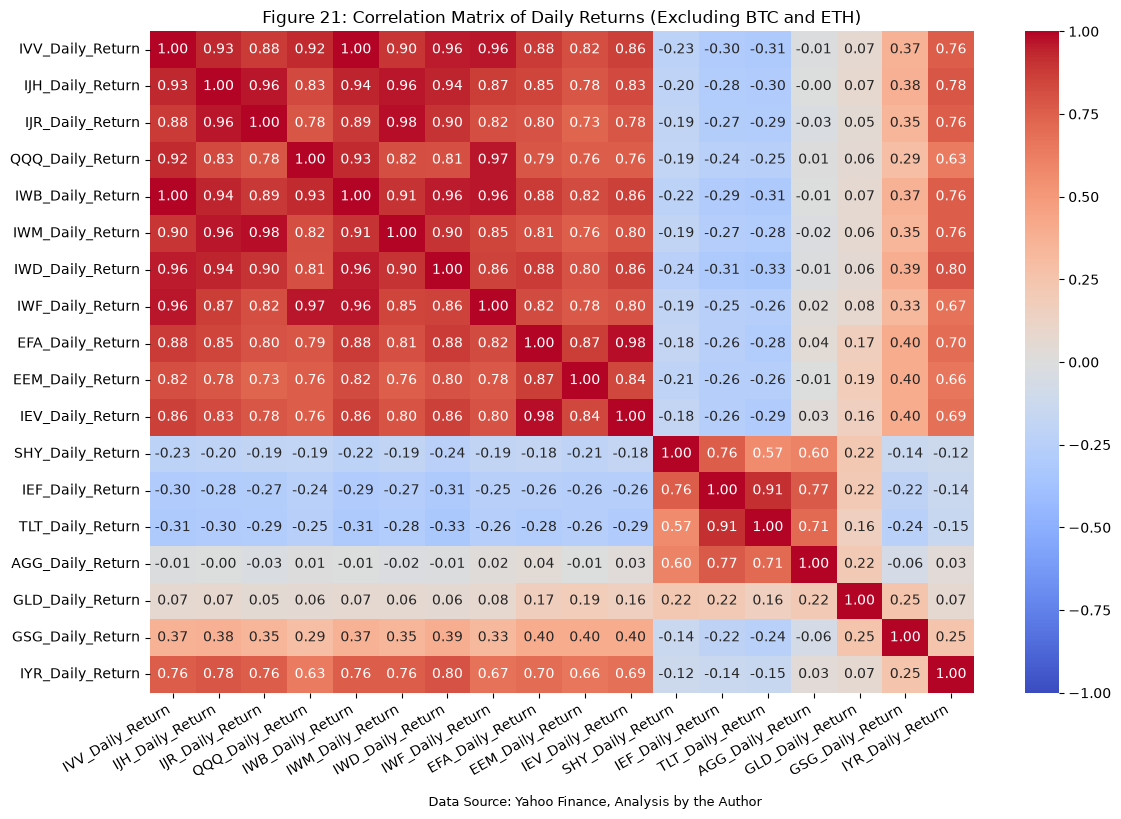

In [10]:
plot_heatmap(
    df=correlation_matrix_no_crypto,
    title=f"Figure {next(figure_number)}: Correlation Matrix of Daily Returns (Excluding BTC and ETH)",
    caption=f"Data Source: Yahoo Finance, Analysis by the Author",
)

We'll now include the BTC and ETH data and recalculate the correlation matrix and heatmap. Keep in mind that the BTC and ETH data only goes back to 2014 and 2017 respectively, so the correlation matrix will be calculated using a shorter time period than the other assets.

In [11]:
# Print the shape of the fund_data_daily_returns DataFrame to confirm that the rows with missing data have been dropped
print(f"Shape of fund_data_daily_returns: {fund_data_daily_returns_all.shape}")
print(f"Rows to drop due to missing data: {fund_data_daily_returns_all.dropna().shape}")

# Drop the NaN values
fund_data_daily_returns = fund_data_daily_returns_all.dropna()

# Calculate the correlation matrix of the daily returns
correlation_matrix = fund_data_daily_returns.corr()

display(Markdown(f"Table {next(table_number)}: Correlation Matrix of Daily Returns (Including BTC and ETH)"))
display(correlation_matrix)

Shape of fund_data_daily_returns: (8334, 20)
Rows to drop due to missing data: (2253, 20)


Table 3: Correlation Matrix of Daily Returns (Including BTC and ETH)

,IVV_Daily_Return,IJH_Daily_Return,IJR_Daily_Return,QQQ_Daily_Return,IWB_Daily_Return,IWM_Daily_Return,IWD_Daily_Return,IWF_Daily_Return,EFA_Daily_Return,EEM_Daily_Return,IEV_Daily_Return,SHY_Daily_Return,IEF_Daily_Return,TLT_Daily_Return,AGG_Daily_Return,GLD_Daily_Return,GSG_Daily_Return,IYR_Daily_Return,BTC-USD_Daily_Return,ETH-USD_Daily_Return
IVV_Daily_Return,1.00,0.90,0.84,0.93,1.00,0.86,0.92,0.96,0.85,0.75,0.82,-0.04,-0.11,-0.14,0.14,0.12,0.29,0.73,0.30,0.33
IJH_Daily_Return,0.90,1.00,0.96,0.77,0.91,0.96,0.94,0.80,0.83,0.71,0.81,-0.04,-0.10,-0.13,0.16,0.11,0.29,0.77,0.28,0.30
IJR_Daily_Return,0.84,0.96,1.00,0.70,0.85,0.98,0.90,0.73,0.78,0.65,0.76,-0.02,-0.09,-0.12,0.16,0.09,0.28,0.73,0.28,0.30
QQQ_Daily_Return,0.93,0.77,0.70,1.00,0.93,0.77,0.75,0.98,0.76,0.74,0.72,-0.02,-0.06,-0.09,0.14,0.14,0.22,0.57,0.31,0.34
IWB_Daily_Return,1.00,0.91,0.85,0.93,1.00,0.88,0.93,0.96,0.85,0.75,0.82,-0.04,-0.10,-0.13,0.15,0.12,0.28,0.73,0.30,0.33
IWM_Daily_Return,0.86,0.96,0.98,0.77,0.88,1.00,0.89,0.79,0.80,0.70,0.77,-0.01,-0.07,-0.10,0.17,0.13,0.28,0.72,0.31,0.33
IWD_Daily_Return,0.92,0.94,0.90,0.75,0.93,0.89,1.00,0.78,0.85,0.69,0.83,-0.05,-0.13,-0.17,0.13,0.11,0.32,0.80,0.26,0.28
IWF_Daily_Return,0.96,0.80,0.73,0.98,0.96,0.79,0.78,1.00,0.77,0.73,0.74,-0.02,-0.07,-0.09,0.15,0.13,0.22,0.61,0.31,0.34
EFA_Daily_Return,0.85,0.83,0.78,0.76,0.85,0.80,0.85,0.77,1.00,0.82,0.98,0.03,-0.03,-0.08,0.22,0.25,0.27,0.68,0.29,0.32
EEM_Daily_Return,0.75,0.71,0.65,0.74,0.75,0.70,0.69,0.73,0.82,1.00,0.79,0.01,-0.05,-0.08,0.16,0.27,0.26,0.51,0.26,0.30


And then the heatmap:

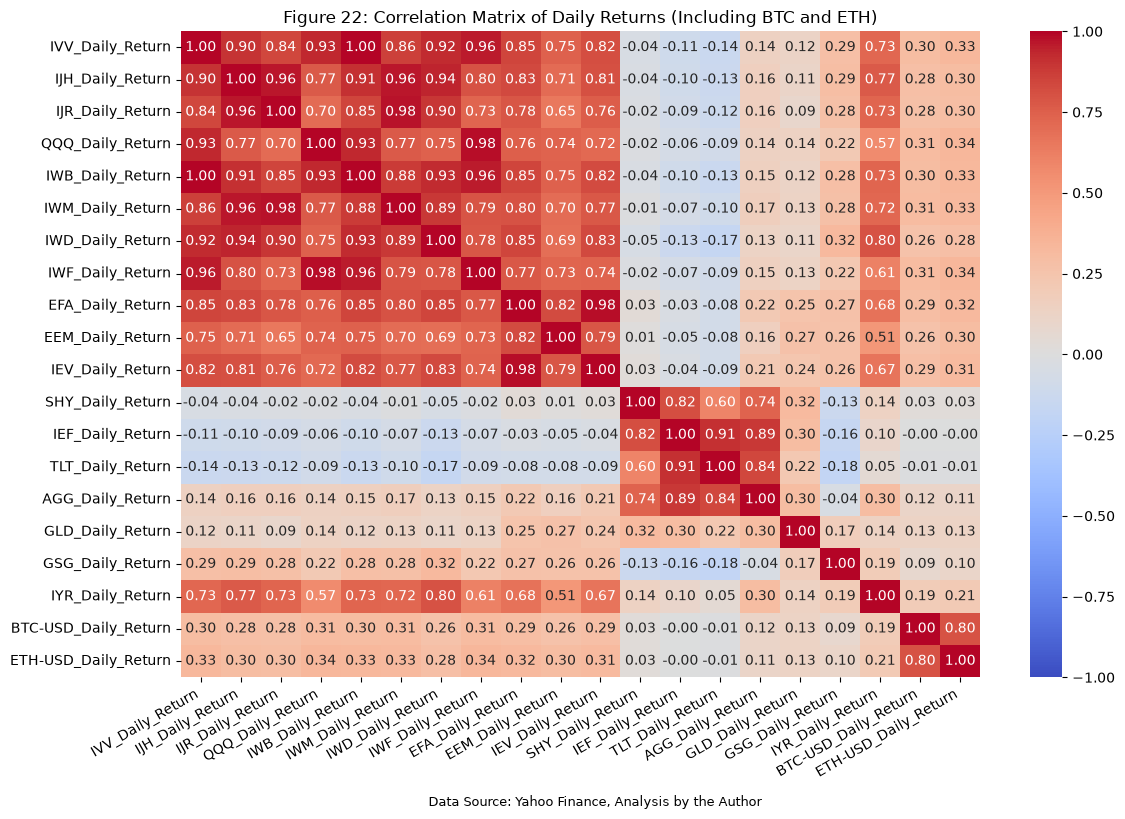

In [12]:
plot_heatmap(
    df=correlation_matrix,
    title=f"Figure {next(figure_number)}: Correlation Matrix of Daily Returns (Including BTC and ETH)",
    caption=f"Data Source: Yahoo Finance, Analysis by the Author",
)

These are interesting results, but expected. The stock funds tend to have low correlations with the bond funds, the commodities don't really correlate with anything, etc. But we know that the correlations between these asset classes have changed over time, so let's take a look at how the correlations have evolved over time by calculating rolling correlations.

## Calculate Rolling Correlations

Next, we will calculate the rolling correlations for several different periods:

* 3 days
* 1 week
* 2 weeks
* 1 month
* 3 month
* 6 month
* 1 year
* 5 years
* 10 years

In [13]:
# Define rolling windows in trading days
rolling_windows = {
    "3d": 3,  # 3 days (~3 trading days)
    "1w": 5,  # 1 week (~5 trading days)
    "2w": 10,  # 2 weeks (~10 trading days)
    "1m": 21,  # 1 month (~21 trading days)
    "3m": 63,  # 3 months (~63 trading days)
    "6m": 126,  # 6 months (~126 trading days)
    "1y": 252,  # 1 year (~252 trading days)
    "5y": 1260,  # 5 years (~1260 trading days)
    "10y": 2520,  # 10 years (~2520 trading days)
}

We'll pair down the list of funds to only include the high correlation US equity funds that make up the S&P 1500 index (IVV, IJH, IJR).

In [14]:
# Create temp list for tickers
tickers = ["IVV", "IJH", "IJR"]
pairs = list(combinations(tickers, 2))

# Create empty dictionary to store rolling correlation results
rolling_corr_results = {}

# Create empty DataFrame to store rolling correlation results
rolling_corr_results_df = pd.DataFrame()

# Calculate rolling correlations for each pair of tickers and each rolling window
for ticker1, ticker2 in pairs:
    try:
        temp_df = fund_data_daily_returns_no_crypto[
            [f"{ticker1}_Daily_Return", f"{ticker2}_Daily_Return"]
        ].dropna()
    except Exception as e:
        print(f"Error creating temp_df for {ticker1} and {ticker2}: {e}")
        continue

    for window_name, window_size in rolling_windows.items():
        try:
            rolling_corr = (
                temp_df[f"{ticker1}_Daily_Return"]
                .rolling(window=window_size)
                .corr(temp_df[f"{ticker2}_Daily_Return"])
            )

            # print(tickers_dict[f"{ticker1}"])
            # print(tickers_dict[f"{ticker2}"])

            rolling_corr_results[
                f"{ticker1}_{ticker2}_{window_name}"
            ] = rolling_corr
            rolling_corr_results_df = pd.concat(
                [
                    rolling_corr_results_df,
                    rolling_corr.to_frame(name=f"{ticker1}_{ticker2}_{window_name}"),
                ],
                axis=1,
            )

        except Exception as e:
            print(
                f"Error calculating rolling correlation for {ticker1} and {ticker2} with window {window_name}: {e}"
            )

display(Markdown(f"Table {next(table_number)}: Rolling Correlations"))
display(rolling_corr_results_df)

Table 4: Rolling Correlations

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IVV_IJR_10y,IJH_IJR_3d,IJH_IJR_1w,IJH_IJR_2w,IJH_IJR_1m,IJH_IJR_3m,IJH_IJR_6m,IJH_IJR_1y,IJH_IJR_5y,IJH_IJR_10y
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.98,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-23,0.98,0.83,0.86,0.76,0.80,0.78,0.80,0.88,0.90,-0.45,...,0.83,-0.25,0.53,0.84,0.86,0.90,0.90,0.93,0.97,0.96
2026-10-26,0.98,0.91,0.89,0.78,0.80,0.78,0.80,0.88,0.90,0.07,...,0.83,0.28,0.54,0.83,0.86,0.91,0.90,0.93,0.97,0.96
2026-10-27,0.99,0.98,0.89,0.76,0.78,0.78,0.80,0.88,0.90,0.99,...,0.83,0.97,0.25,0.84,0.86,0.90,0.90,0.93,0.97,0.96


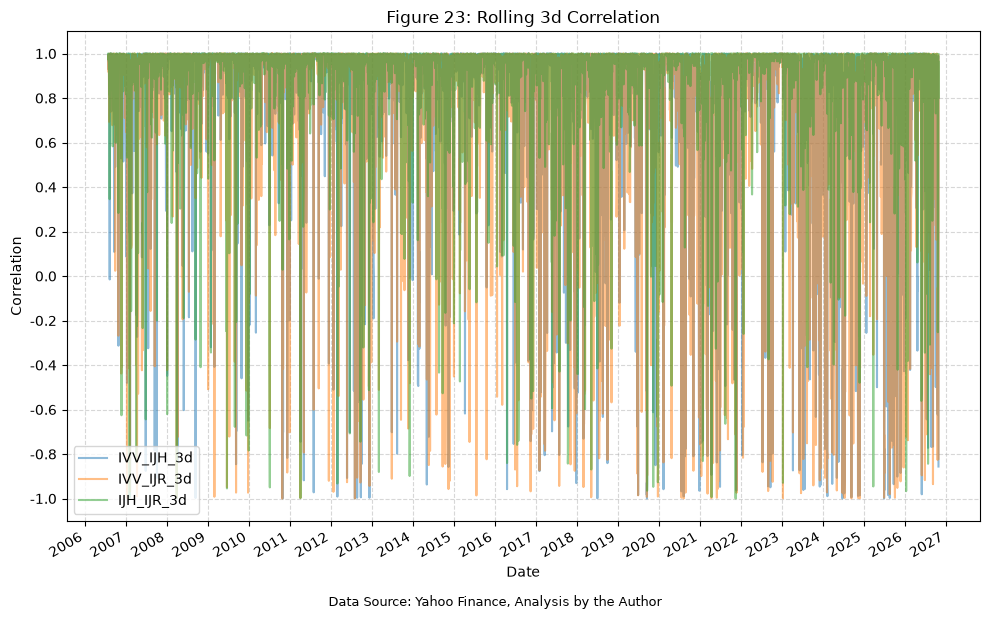

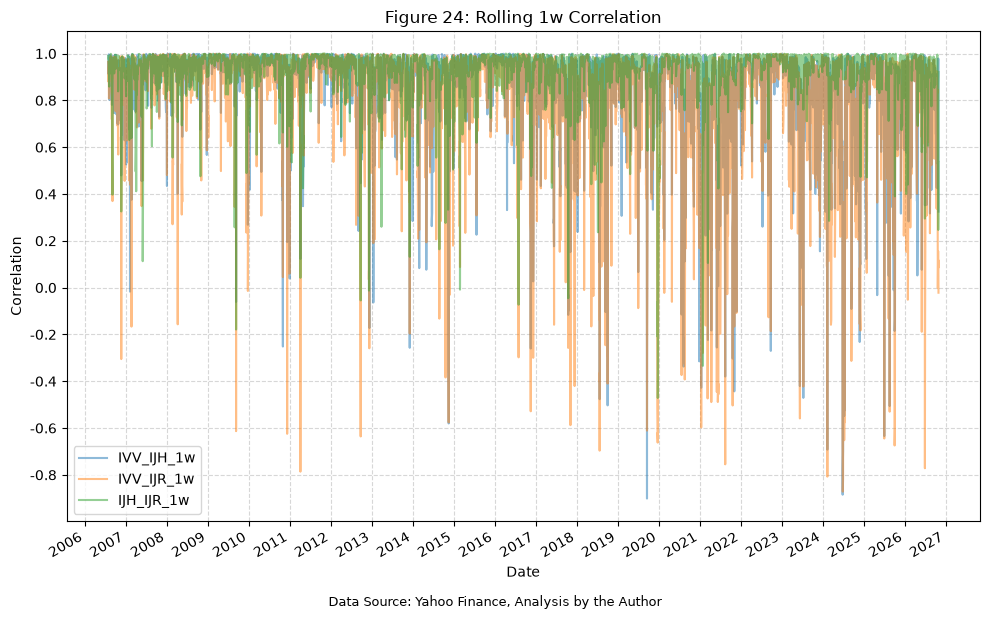

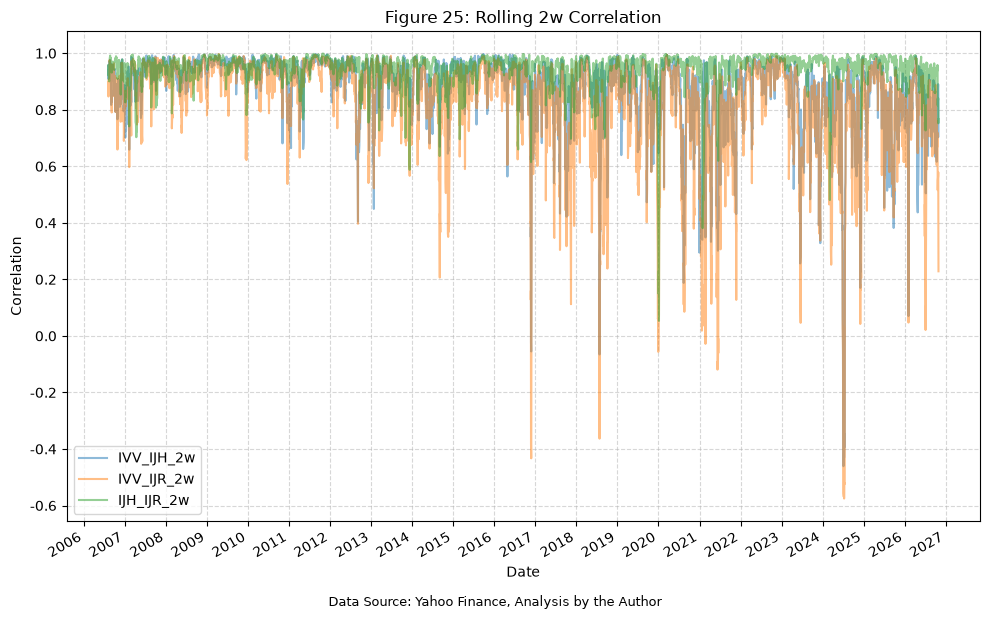

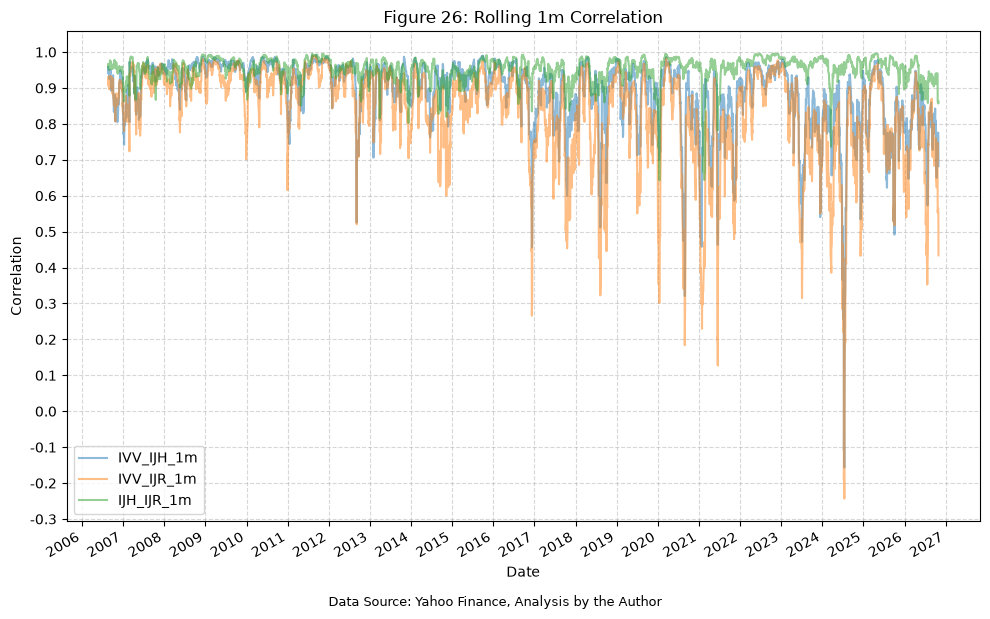

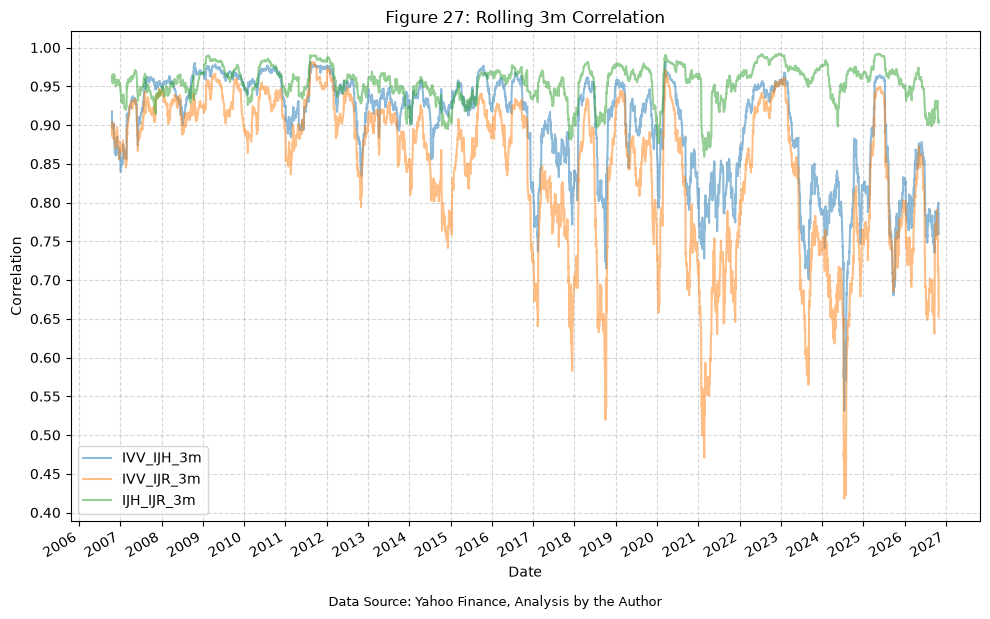

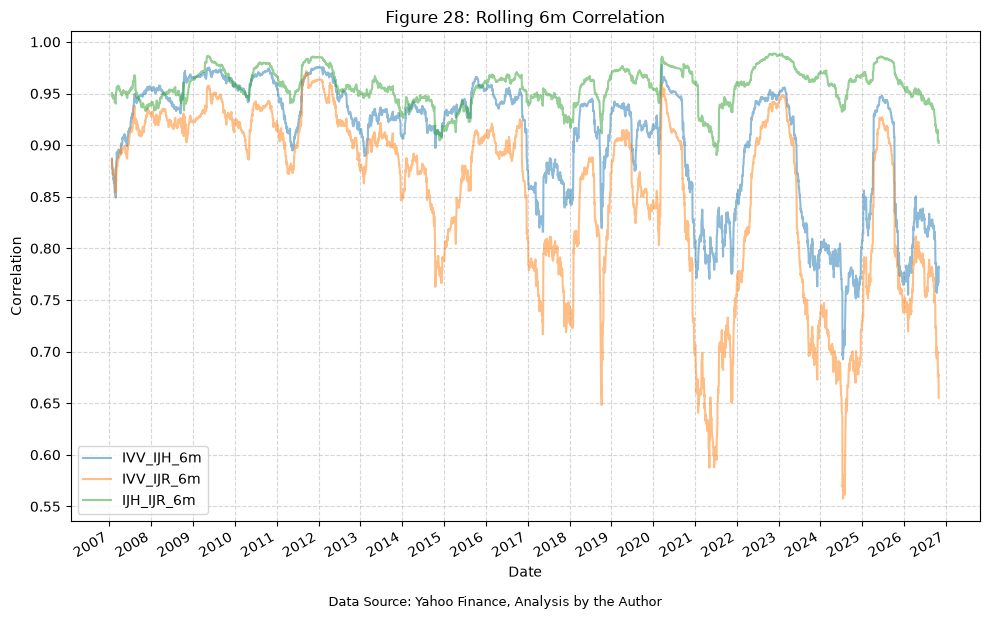

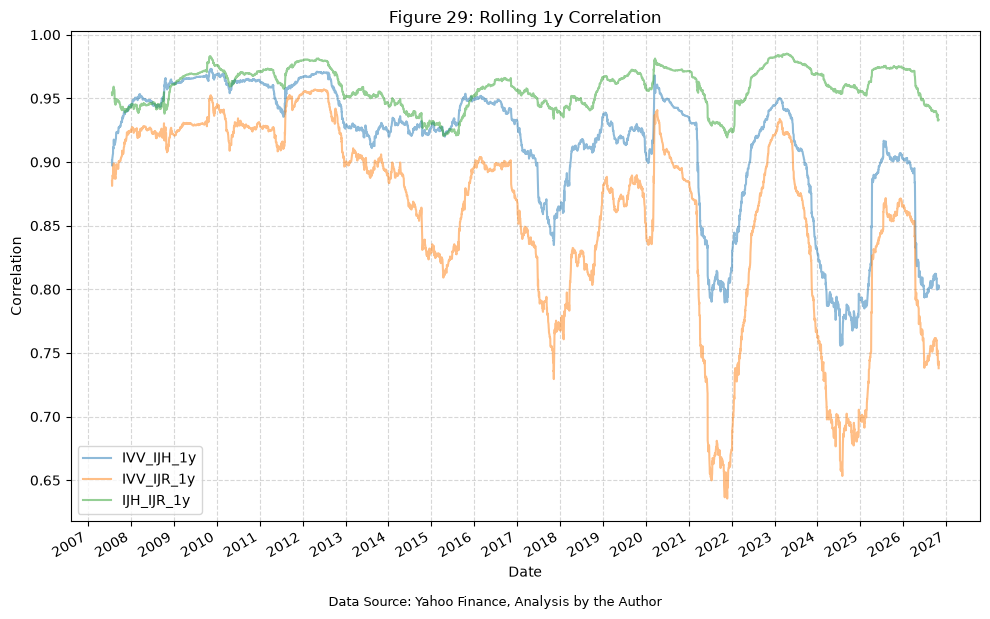

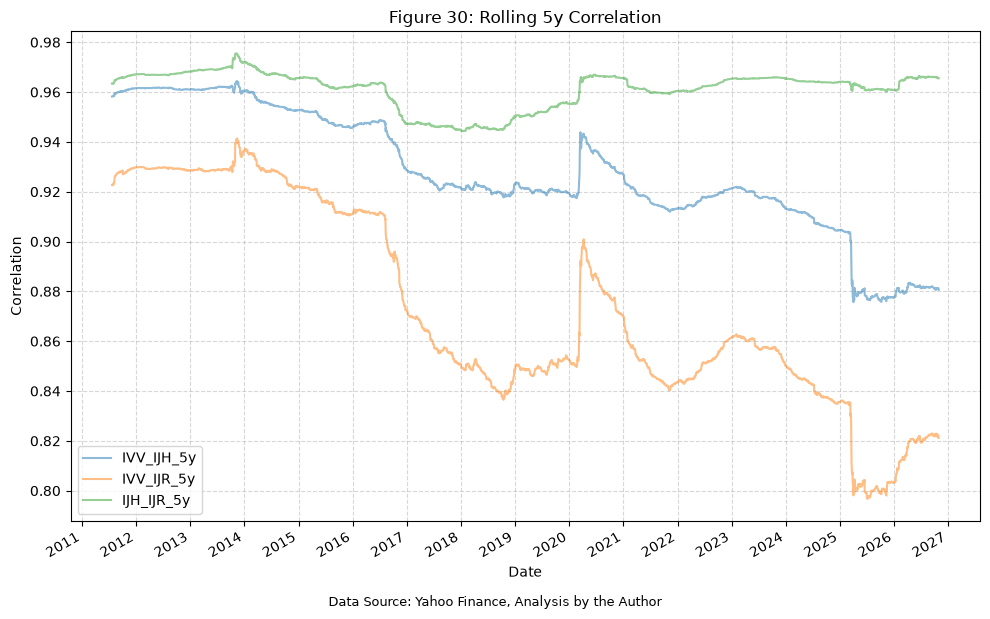

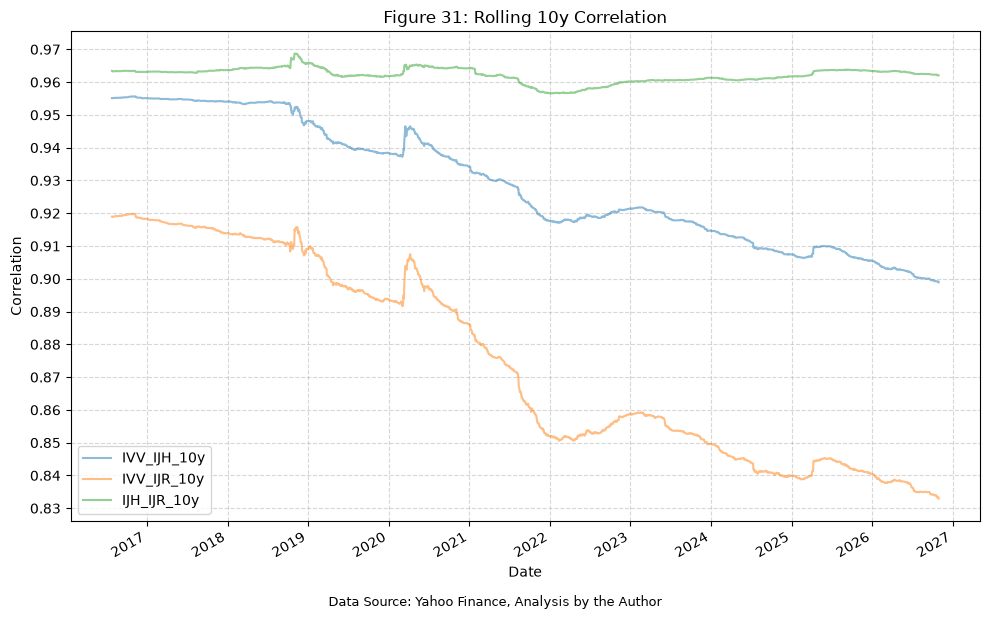

In [15]:
for window in rolling_windows.keys():
    plot_time_series(
        df=rolling_corr_results_df,
        plot_start_date=None,
        plot_end_date=None,
        plot_columns=[col for col in rolling_corr_results_df.columns if f"{window}" in col],
        title=f"Figure {next(figure_number)}: Rolling {window} Correlation",
        x_label="Date",
        x_format="Year",
        x_tick_spacing=1,
        x_tick_start=None,
        x_tick_rotation=30,
        y_label="Correlation",
        y_format="Decimal",
        y_format_decimal_places="Auto",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

With the above plots, we can see that there are periods of time when the correlations abruptly increase or decrease, such as:

* Early-mid 2007 (the start of the financial crisis)
* Mid 2011 (the European debt crisis)
* Late 2015 into 2016
* Late 2018 (rate hikes?)
* Early 2020 (COVID-19 pandemic)
* Late 2022 into early 2023 (rate hikes, recession fears, COVID tech bubble, etc.)
* Mid 2024 (banking crisis, rate hikes)
* Early 2025 (Liberation day)

We're not necessarily looking to explain away each of these time periods or delve into the macro factors that may have been at play or driving the correlations, but we are more interested in the change in correlation over time as a response to some kind of market shock or event.

## Conclusion

Overall, this was a brief but interesting study that dove into the historical correlations amongst a wide range of asset classes. The full period correlation matrices gave us the expected picture, while the rolling correlations showed how much those relationships change over time, particularly in response to market shocks.

## Future Investigation

In [part 2](/posts/asset-class-return-correlations-part-2/), we'll investigate whether the rolling correlations can be used as a signal, by building a "total correlation" metric, looking at future returns based on that metric, and developing a trading strategy.

## References

None